![Banner](../../../../Images/Banner/07_remote_sensing/09_11_banner_rs_foundation_models.png)

# Prithvi, SSL4EO, SatlasPretrain and Scale-MAE on Sentinel-2

Four families of optical encoders cover most of what is used today on multispectral imagery:
NASA and IBM's Prithvi-EO, pretrained on Harmonized Landsat Sentinel-2 (HLS); SSL4EO-S12,
pretrained on Sentinel-2 with self-supervised objectives; SatlasPretrain, pretrained with
millions of labels; and Scale-MAE, pretrained on high-resolution RGB at many scales. This notebook
runs all four on the same Iowa Corn Belt scenes at their native resolution, asks how much crop
information their frozen patch features hold early and late in the season, shows why random
cross-validation flatters them, clusters their embeddings without labels, and finally fine-tunes
Prithvi into a crop segmentation model and compares it with a U-Net trained from scratch, with
few and with many labels.

## Overview

### The four optical encoders

| Model | Pretraining data | Objective | Architecture | Input |
|---|---|---|---|---|
| Prithvi-EO-2.0-300M | 4.2 million HLS time series, global | masked autoencoding with 3-D patches | ViT-L, 24 blocks, 1024-d | 6 HLS bands, 30 m, 1 to 4 dates |
| Prithvi-EO-1.0-100M | HLS over the contiguous US | masked autoencoding | ViT-B, 12 blocks, 768-d | 6 HLS bands, 3 dates |
| SSL4EO-S12 ViT-S/16 | 250,000 places x 4 seasons of Sentinel-2 L1C | DINO self-distillation | ViT-S, 384-d | 13 Sentinel-2 bands |
| SatlasPretrain Swin-T | 302 million labels on Sentinel-2 and NAIP | supervised multi-task | Swin-v2-T, 768-d | 9 Sentinel-2 bands |
| Scale-MAE ViT-L | fMoW RGB at 0.3 to 3 m | masked autoencoding with GSD encoding | ViT-L, 1024-d | RGB |

Prithvi's **3-D patch embedding** turns a stack of dates into tokens of size time x 16 x 16, so
the same weights read one date or four. SSL4EO pretrains on four seasonal views of every place,
so its features should be robust to phenology. Satlas is the odd one out: its weights come from
supervised training on labels such as land cover, roads and solar farms, which makes its features
task-shaped. Scale-MAE never saw multispectral or 20 m data; it is here to show what happens when
a model is used far from its pretraining distribution.

SpectralGPT and SatMAE are in the catalog but need the authors' code (`fm.model_info("spectralgpt")`).

### Patch features at native resolution

Notebook 09_11_03 resized 32 pixel chips to 224 pixels, which shows the model fields at an apparent
resolution of about 3 m. Here every model reads 224 or 256 pixel chips of 20 m data, the scale it
was trained near, and `embed_raster(dense=True)` returns its patch features: 16 pixel (320 m)
patches for the ViTs, 32 pixel (640 m) cells for the Swin. All are averaged to the same 640 m grid
so the models can be compared cell by cell.

### Early season is the hard case

By late August corn and soybeans look different in every band, and notebook 09_11_03 showed a
band-mean baseline at 99 % accuracy. On 22 June both are small plants on bare soil, and telling
them apart needs texture, field patterns and subtle spectral differences: the situation where
pretrained features can help.

### Fine-tuning and label efficiency

A frozen encoder plus a light decoder trains quickly and needs few labels; updating the whole
encoder (full fine-tuning) can adapt it further but needs more labels and memory. A U-Net trained
from scratch is the classical baseline. The label efficiency curve, accuracy against the number
of labelled chips, is where pretraining should pay off.

## Optical Encoders with GeoLattice

| Step | GeoLattice |
|---|---|
| prepare inputs per model | `fm.prepare(name, da)`, `embed_raster(norm="model")` |
| patch features as a map | `enc.embed_raster(da, dense=True)` |
| probes | `fm.linear_probe`, `fm.knn_probe` with `groups=` |
| clustering | `fm.cluster_embeddings` |
| encoder + decoder | `fm.segmentation_model(num_classes, backbone=...)` (TerraTorch UperNet) |
| baseline | `geolattice.rsense.dl.UNet` |

### Learning objectives

1. Run four optical encoders on the same scenes with their own input contracts.
2. Compare their patch features with spatial linear and kNN probes, early and late in the season.
3. Show how random cross-validation inflates scores on spatially correlated data.
4. Cluster embeddings without labels and score the clusters against the CDL.
5. Fine-tune Prithvi with a segmentation decoder, frozen and unfrozen.
6. Draw a label efficiency curve against a U-Net trained from scratch.

### Data

| Dataset | Content |
|---|---|
| Corn Belt Sentinel-2 cube | Iowa, 30 x 29 km, 10 bands at 20 m; 22 June and 26 August 2025 |
| Cropland Data Layer 2025 | six crop and land cover groups on the same grid |

### Contents

- Setup
- Two dates of the Corn Belt
- Patch features from four encoders
- How much crop information do they hold?
- Random folds flatter
- Clusters without labels
- Fine-tuning Prithvi for crop segmentation
- Label efficiency
- Summary and exercises

## Setup

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README. It also uses `geolattice[rsense-foundation]`, which no GeoLattice option installs: `pip install "geolattice[rsense-foundation]"`.

In [1]:
import os  # environment variables
os.environ.setdefault("USE_TF", "0")  # keep transformers from loading TensorFlow
import time  # timing
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import torch  # PyTorch: every model runs on it
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.foundation_models as fm  # catalog, loaders, embeddings and probes

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DATA = Path("../../../../Data/08_remote_sensing")  # remote sensing data folder
IC = DATA / "09_09_image_classification"  # data shared with the image classification chapter
CAP = DATA / "08_11_Capstones"  # data shared with the capstones
OUT = Path("outputs")  # results written by this notebook
OUT.mkdir(exist_ok=True)  # create it if needed
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # run models on the GPU when there is one
SEED = 0  # one seed for every random step
np.random.seed(SEED)  # NumPy
torch.manual_seed(SEED)  # PyTorch

print("GeoLattice", geolattice.__version__, "| PyTorch", torch.__version__, "| device", DEVICE)  # versions used
if DEVICE == "cuda":  # name the GPU
    print("GPU:", torch.cuda.get_device_name(0))  # GPU model

CUBE = IC / "Corn_belt" / "cache_20m"  # Corn Belt cubes on the 20 m grid
CLASSES = ["Corn", "Soybeans", "Grass/pasture", "Developed", "Wetland/forest", "Other"]  # CDL groups 0 to 5
COLORS = ["#e6c229", "#2a9d3c", "#b9e08b", "#d7301f", "#1f5fbf", "#7f7f7f"]  # one colour per class
DATES = {"June": "2025-06-22", "August": "2025-08-26"}  # early and late season
CELL = 32  # comparison cell in 20 m pixels (640 m)

GeoLattice 0.3.47 | PyTorch 2.14.0+cu132 | device cuda
GPU: NVIDIA RTX A5500 Laptop GPU


## Two dates of the Corn Belt

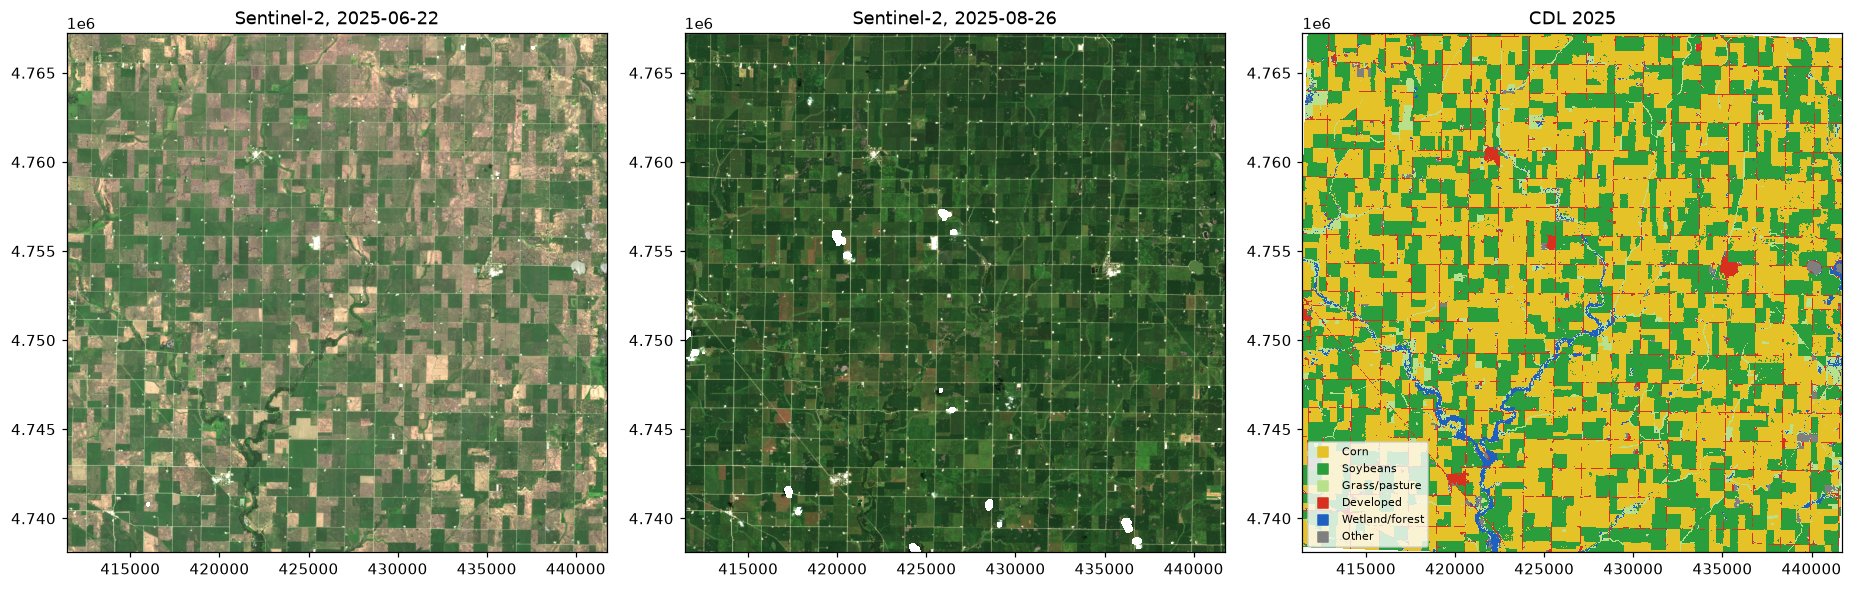

In [2]:
cube = xr.open_dataarray(CUBE / "s2_20m.nc")  # (time, band, y, x) reflectance, lazily
s2 = {k: cube.sel(time=v).drop_vars("time").load().rio.write_crs("EPSG:32615") for k, v in DATES.items()}  # two scenes
cdl = xr.open_dataset(CUBE / "labels_20m.nc")["cdl"].sel(year=2025).load()  # CDL 2025 groups
NY, NX = -(-cdl.shape[0] // CELL), -(-cdl.shape[1] // CELL)  # cells per column and row
ext = [float(cdl.x.min()), float(cdl.x.max()), float(cdl.y.min()), float(cdl.y.max())]  # map extent
from matplotlib.colors import ListedColormap  # discrete colours

fig, ax = plt.subplots(1, 3, figsize=(17, 5.5))  # three panels
for a, (k, da) in zip(ax, s2.items()):  # each date
    a.imshow(np.clip(da.sel(band=["red", "green", "blue"]).transpose("y", "x", "band").values / 0.15, 0, 1), extent=ext)  # true colour
    a.set_title(f"Sentinel-2, {DATES[k]}")  # title
ax[2].imshow(np.ma.masked_less(cdl.values, 0), cmap=ListedColormap(COLORS), vmin=-0.5, vmax=5.5, extent=ext,
             interpolation="nearest"); ax[2].set_title("CDL 2025")  # reference
for c, col in zip(CLASSES, COLORS):  # legend
    ax[2].scatter([], [], color=col, marker="s", label=c)  # empty handle
ax[2].legend(fontsize=7, loc="lower left"); plt.tight_layout(); plt.show()  # draw

In June the fields are mostly soil brown with the first green rows; by late August the canopy is
closed and corn (darker, bluish green) and soybeans (lighter, yellowish green) differ clearly.

Every 640 m cell gets the majority CDL class when it covers at least 60 % of the cell, and a spatial
block (5.8 km) for cross-validation, as in notebook 09_11_03.

In [3]:
pad = np.full((NY * CELL, NX * CELL), -1, cdl.dtype); pad[:cdl.shape[0], :cdl.shape[1]] = cdl.values  # padded CDL
blocks = pad.reshape(NY, CELL, NX, CELL).transpose(0, 2, 1, 3).reshape(NY * NX, -1)  # pixels per cell
counts = np.stack([(blocks == k).sum(1) for k in range(len(CLASSES))], 1)  # pixels per class
major, purity = counts.argmax(1), counts.max(1) / blocks.shape[1]  # majority class and its share
gy, gx = np.divmod(np.arange(NY * NX), NX)  # cell row and column
group = (gy // 9) * 10 + gx // 9  # 9 x 9 cell blocks
ok = (purity >= 0.6) & np.isin(major, [0, 1])  # pure corn or soybean cells
y_ok, g_ok = major[ok], group[ok]  # labels and blocks
print(ok.sum(), "cells:", dict(zip(["Corn", "Soybeans"], np.bincount(y_ok))), "|", len(np.unique(g_ok)), "blocks")  # summary

1449 cells: {'Corn': np.int64(940), 'Soybeans': np.int64(509)} | 30 blocks


## Patch features from four encoders

Each model reads the scene through its own contract (`norm="model"`) in chips of its own size, and
returns patch features that are averaged to the 640 m grid. The four models are loaded one at a
time to keep GPU memory free.

In [4]:
MODELS = ["prithvi-eo-2.0-300m", "ssl4eo-s12-vits16-dino", "satlas-swint-s2-ms", "scale-mae"]  # the encoders


def cell_features(enc, da):  # patch features averaged to the 640 m grid, as (cells, D)
    d = enc.embed_raster(da, dense=True, norm="model", batch_size=8)  # (D, y, x) patch map
    f = int(round(d.sizes["y"] / NY))  # patches per cell side (2 for 320 m patches, 1 for 640 m cells) (2 for 320 m patches)
    if f > 1:  # average f x f patches into one cell
        d = d.coarsen(y=f, x=f, boundary="pad").mean()  # 640 m cells
    return d.values[:, :NY, :NX].reshape(d.sizes["embedding"], -1).T  # (cells, D)


feats, info = {}, []  # features and run information
for n in MODELS:  # every model
    enc = fm.load_model(n, device=DEVICE)  # load once per model
    for k, da in s2.items():  # both dates
        t0 = time.perf_counter()  # start the clock
        feats[(n, k)] = cell_features(enc, da)  # (cells, D)
        info.append({"model": n, "date": k, "dim": feats[(n, k)].shape[1], "seconds": round(time.perf_counter() - t0, 1)})  # record
    del enc; torch.cuda.empty_cache() if DEVICE == "cuda" else None  # free memory
cube_bands = {k: np.nan_to_num(da.coarsen(y=CELL, x=CELL, boundary="pad").mean().values[:, :NY, :NX].reshape(10, -1).T)
              for k, da in s2.items()}  # baseline: mean reflectance per cell
pd.DataFrame(info).pivot(index="model", columns="date", values="seconds").assign(dim=pd.DataFrame(info).groupby("model")["dim"].first())  # run times

date,August,June,dim
model,,,
prithvi-eo-2.0-300m,0.8,0.9,1024
satlas-swint-s2-ms,0.3,0.4,768
scale-mae,0.8,0.8,1024
ssl4eo-s12-vits16-dino,0.4,0.4,384


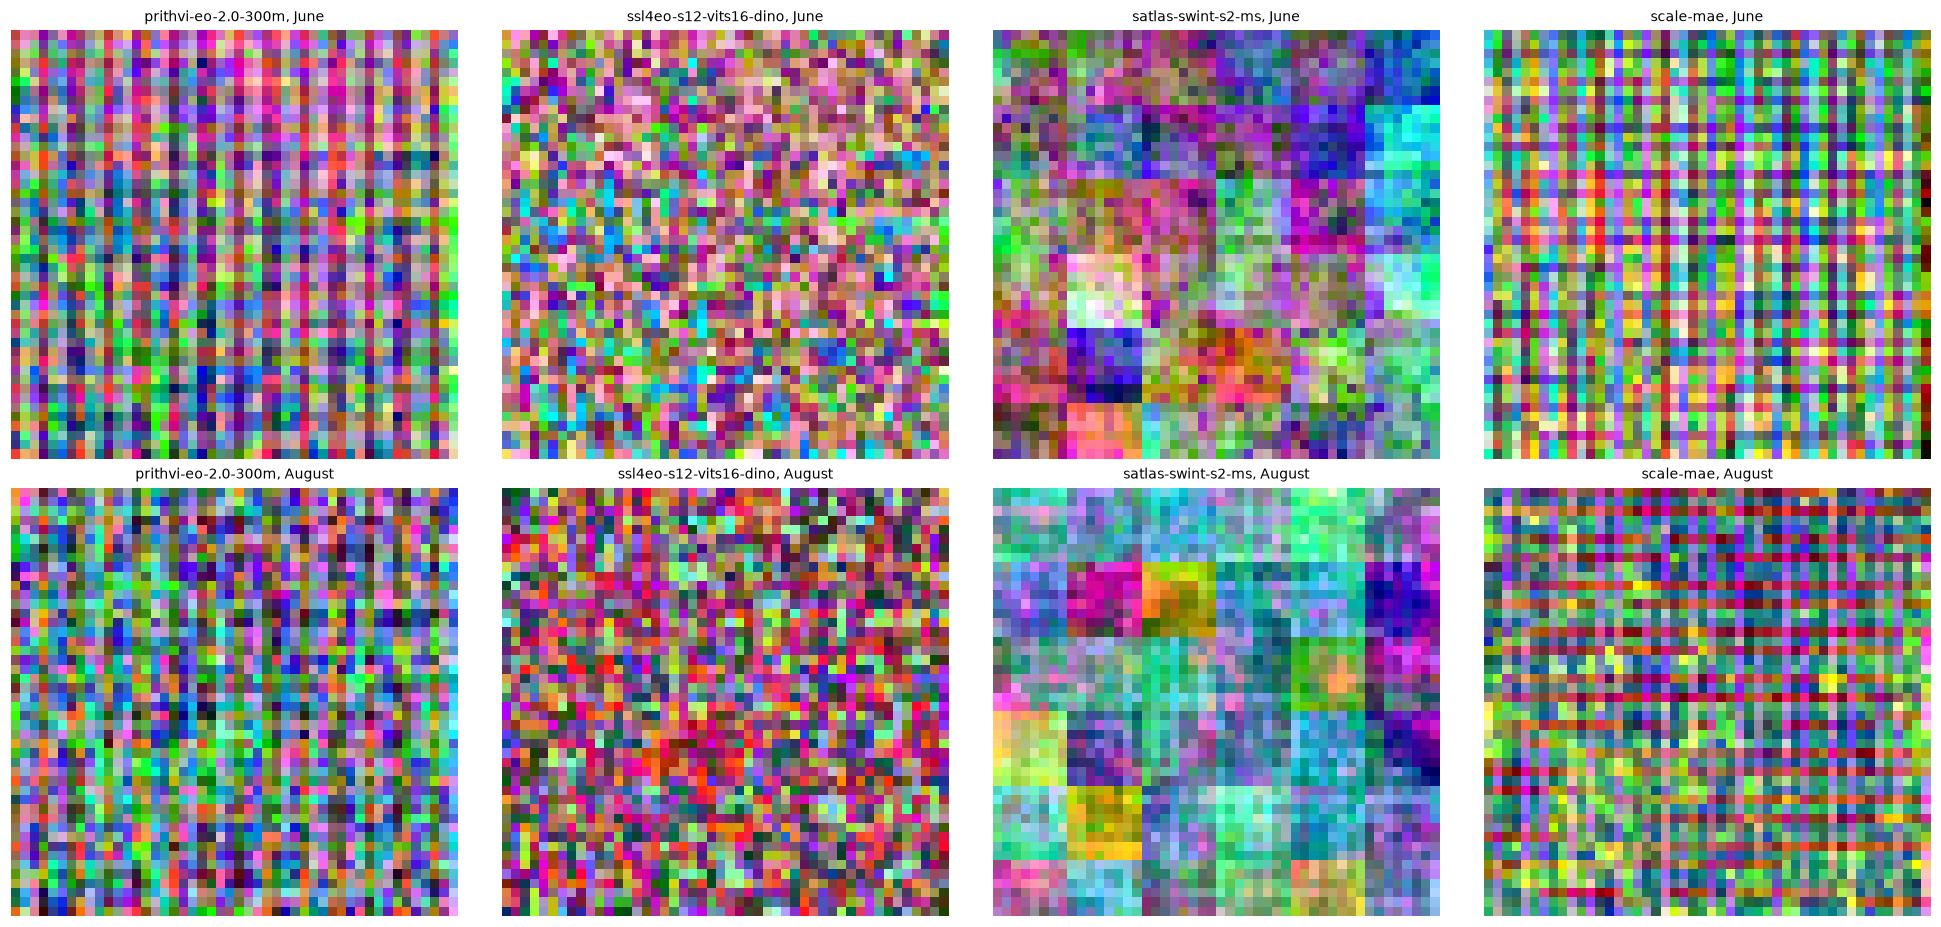

In [5]:
fig, ax = plt.subplots(2, 4, figsize=(18, 8.5))  # models x dates
for j, n in enumerate(MODELS):  # every model
    for i, k in enumerate(DATES):  # every date
        F = feats[(n, k)].T.reshape(-1, NY, NX)  # back to a map
        m = xr.DataArray(F, dims=("embedding", "y", "x"))  # embedding map
        ax[i, j].imshow(fm.embedding_rgb(m).transpose("y", "x", "band"), interpolation="nearest")  # PCA colours
        ax[i, j].set_title(f"{n}, {k}", fontsize=9); ax[i, j].axis("off")  # labels
plt.tight_layout(); plt.show()  # draw

The colours of different models are not comparable (each PCA has its own axes), but the structure
of each map is. Prithvi and SSL4EO vary from cell to cell the way the fields do. Satlas paints one
block per 256 pixel chip: its deepest Swin features describe the whole chip, so neighbouring cells
inside a chip look alike and cells across a chip boundary differ. Scale-MAE shows regular stripes along
rows and columns, the trace of its position encoding: on inputs far from its training data (RGB
photographs at 0.3 to 3 m) the position of a patch says more than its content.

## How much crop information do they hold?

Linear and kNN probes with 5-fold spatial-block cross-validation, on each date, for every encoder and
for the band-mean baseline.

In [6]:
rows = []  # probe results
for k in DATES:  # each date
    inputs = {"band means": cube_bands[k]} | {n: feats[(n, k)] for n in MODELS}  # baseline and encoders
    for n, X in inputs.items():  # every input
        lp = fm.linear_probe(X[ok], y_ok, groups=g_ok)  # spatial linear probe
        kp = fm.knn_probe(X[ok], y_ok, groups=g_ok, k=7)  # spatial kNN probe
        rows.append({"date": k, "input": n, "linear F1": lp["mean"]["f1_macro"], "kNN accuracy": kp["mean"]})  # record
probe = pd.DataFrame(rows).pivot(index="input", columns="date").round(3)  # inputs x (metric, date)
probe

linear F1        kNN accuracy       
date                      August   June       August   June
input                                                      
band means                 0.990  0.889        0.979  0.887
prithvi-eo-2.0-300m        0.998  0.958        0.993  0.931
satlas-swint-s2-ms         0.916  0.905        0.797  0.812
scale-mae                  0.947  0.939        0.802  0.898
ssl4eo-s12-vits16-dino     0.992  0.955        0.983  0.938

In August every input is near the ceiling: the canopy spectra alone separate the crops, as in
notebook 09_11_03. In June the differences appear. Prithvi and SSL4EO patch features reach a macro F1
of about 0.96 against 0.89 for the band means. The two models were pretrained on multispectral
satellite time series that include early-season scenes. Scale-MAE (RGB only, trained on very high
resolution photographs) and Satlas (whose features describe whole chips) land in between. The kNN
probe, which uses distances in the raw embedding space, keeps the same order but with lower scores
for Satlas and Scale-MAE: their embedding spaces are organised by something other than the crop.

## Random folds flatter

The same probes with random folds instead of spatial blocks: neighbouring cells, which look alike
and usually belong to the same field pattern, end up in both training and test folds.

In [7]:
rows = []  # random vs spatial
for n, X in ({"band means": cube_bands["June"]} | {m: feats[(m, "June")] for m in MODELS}).items():  # June inputs
    spatial = fm.linear_probe(X[ok], y_ok, groups=g_ok)["mean"]["f1_macro"]  # blocks
    random = fm.linear_probe(X[ok], y_ok)["mean"]["f1_macro"]  # random folds
    rows.append({"input": n, "spatial folds": spatial, "random folds": random, "inflation": random - spatial})  # record
pd.DataFrame(rows).set_index("input").round(3)  # how much random folds flatter

,spatial folds,random folds,inflation
input,,,
band means,0.889,0.896,0.007
prithvi-eo-2.0-300m,0.958,0.967,0.008
ssl4eo-s12-vits16-dino,0.955,0.964,0.008
satlas-swint-s2-ms,0.905,0.927,0.022
scale-mae,0.939,0.955,0.016


Random folds score every input higher, by about one point for the band means and the ViTs and two
points for Satlas, whose features are the most spatially smooth (one block per chip). The
inflation is small here because the classes are spatially mixed (corn and soybeans alternate field by
field). With spatially clustered classes, such as forest or towns, the gap is usually much larger,
and only spatial folds give an honest estimate.

## Clusters without labels

`fm.cluster_embeddings` runs k-means on the embeddings with no labels at all. With two clusters on
the corn and soybean cells, the adjusted Rand index (ARI) measures agreement with the CDL: 1 is
perfect, 0 is chance.

In [8]:
from sklearn.metrics import adjusted_rand_score  # cluster agreement

rows = []  # ARI per input and date
for k in DATES:  # each date
    for n, X in ({"band means": cube_bands[k]} | {m: feats[(m, k)] for m in MODELS}).items():  # inputs
        Xs = (X[ok] - X[ok].mean(0)) / (X[ok].std(0) + 1e-9)  # standardize features
        lab = fm.cluster_embeddings(Xs, 2, seed=SEED)  # k-means, two clusters
        rows.append({"date": k, "input": n, "ARI": adjusted_rand_score(y_ok, lab)})  # agreement
pd.DataFrame(rows).pivot(index="input", columns="date", values="ARI").round(3)  # inputs x dates

date,August,June
input,,
band means,0.792,0.443
prithvi-eo-2.0-300m,0.959,0.639
satlas-swint-s2-ms,0.012,0.006
scale-mae,-0.003,-0.005
ssl4eo-s12-vits16-dino,0.804,0.384


Without any labels, two k-means clusters of the Prithvi features reproduce the August corn and
soybean map almost perfectly (ARI about 0.96), and still agree substantially in June (about 0.64).
SSL4EO clusters well in August and less in June. The band means cluster well in August only.
Satlas and Scale-MAE clusters have nothing to do with the crops (ARI near 0): the largest variation
in their embeddings is the chip block or the patch position seen in the maps above. Supervised
probes find the crop signal in those embeddings anyway, but clustering only finds the strongest
structure, so it tells you what an embedding space is organised around.

## Fine-tuning Prithvi for crop segmentation

`fm.segmentation_model` builds Prithvi-EO-2.0 with a UperNet decoder through TerraTorch; the
decoder upsamples patch features back to pixels. Training chips are 224 pixel windows of the June
scene with a stride of 112 pixels, labelled pixel by pixel with the six CDL groups. The western
half trains, the eastern half tests, and chips that straddle the dividing line are dropped so no
pixel is in both.

In [9]:
X_all = fm.prepare("prithvi-eo-2.0-300m", s2["June"])  # 6 HLS bands, Prithvi statistics
lab_da = cdl.astype("float32").expand_dims(band=["cdl"]).where(cdl >= 0)  # labels as a raster, NaN = none
Xc, cy, cx = fm.chip_raster(X_all, chip_size=224, stride=112)  # (n, 6, 224, 224)
Yc, _, _ = fm.chip_raster(lab_da, chip_size=224, stride=112)  # matching label chips
Yc = np.nan_to_num(Yc[:, 0], nan=-1).astype("int64")  # (n, 224, 224), -1 = ignore
cxs = np.repeat(cx[None], len(cy), 0).ravel()  # chip centre x for every chip
mid = float(np.median(cx))  # dividing line
half = 112 * 20.0  # half a chip in metres
train_idx = np.flatnonzero(cxs + half <= mid)  # chips entirely west
test_idx = np.flatnonzero(cxs - half >= mid)  # chips entirely east
print(len(Xc), "chips |", len(train_idx), "train (west) |", len(test_idx), "test (east)")  # split sizes

156 chips | 72 train (west) | 72 test (east)


One training function serves every model: AdamW (with a five times smaller learning rate for a
pretrained encoder that is being fine-tuned), bf16 mixed precision on the GPU, random flips,
cross-entropy that ignores unlabelled pixels, and a fixed number of epochs. The test score is the
mean intersection over union (mIoU) of the classes present in the test area, and the per-class IoU.

In [10]:
from geolattice.rsense.dl import UNet  # U-Net baseline


def run(model, idx, epochs=20, lr=1e-4, batch=8, out=lambda m, x: m(x), encoder_lr=None):  # train, then score
    torch.manual_seed(SEED)  # same shuffles for every model
    model = model.to(DEVICE)  # move to the GPU
    enc_ids = {id(p) for p in getattr(model, "encoder", torch.nn.Module()).parameters()}  # encoder weights, if any
    head = [p for p in model.parameters() if p.requires_grad and id(p) not in enc_ids]  # decoder and head
    body = [p for p in model.parameters() if p.requires_grad and id(p) in enc_ids]  # trainable encoder weights
    groups = [{"params": head, "lr": lr}] + ([{"params": body, "lr": encoder_lr or lr}] if body else [])  # learning rates
    opt = torch.optim.AdamW(groups, weight_decay=0.01)  # optimizer
    loss_fn = torch.nn.CrossEntropyLoss(ignore_index=-1)  # skip unlabelled pixels
    t0 = time.perf_counter()  # start the clock
    for ep in range(epochs):  # training epochs
        model.train()  # training mode
        perm = np.random.default_rng(SEED + ep).permutation(idx)  # shuffle the chips
        for i in range(0, len(perm), batch):  # mini-batches
            b = perm[i:i + batch]  # chip indices
            x, y = torch.as_tensor(Xc[b]).to(DEVICE), torch.as_tensor(Yc[b]).to(DEVICE)  # inputs and labels
            if np.random.default_rng(ep + i).random() < 0.5:  # random horizontal flip
                x, y = x.flip(-1), y.flip(-1)  # flip both
            with torch.autocast(DEVICE, dtype=torch.bfloat16, enabled=DEVICE == "cuda"):  # mixed precision
                loss = loss_fn(out(model, x).float(), y)  # pixel-wise cross-entropy
            opt.zero_grad(); loss.backward(); opt.step()  # update
    secs = time.perf_counter() - t0  # training time
    model.eval(); inter = np.zeros(len(CLASSES)); union = np.zeros(len(CLASSES))  # IoU accumulators
    with torch.no_grad(), torch.autocast(DEVICE, dtype=torch.bfloat16, enabled=DEVICE == "cuda"):  # inference
        for i in range(0, len(test_idx), batch):  # test chips
            b = test_idx[i:i + batch]  # chip indices
            p = out(model, torch.as_tensor(Xc[b]).to(DEVICE)).argmax(1).cpu().numpy()  # predicted classes
            y = Yc[b]; v = y >= 0  # labels and labelled pixels
            for k in range(len(CLASSES)):  # every class
                inter[k] += ((p == k) & (y == k) & v).sum(); union[k] += (((p == k) | (y == k)) & v).sum()  # counts
    iou = np.where(union > 0, inter / np.maximum(union, 1), np.nan)  # IoU per class
    model.cpu(); torch.cuda.empty_cache() if DEVICE == "cuda" else None  # free the GPU
    return {"mIoU": float(np.nanmean(iou)), **{c: iou[k] for k, c in enumerate(CLASSES)}, "train s": secs}  # scores


def prithvi(frozen):  # Prithvi-EO-2.0 + UperNet, encoder frozen or trainable
    m = fm.segmentation_model(len(CLASSES), backbone="prithvi-eo-2.0-300m")  # TerraTorch encoder-decoder
    for p in m.encoder.parameters():  # encoder weights
        p.requires_grad = not frozen  # freeze or train
    return m


seg_out = lambda m, x: m(x).output  # TerraTorch models return an object with .output
results = {"U-Net from scratch": run(UNet(in_channels=6, classes=len(CLASSES)), train_idx, lr=1e-3),
           "Prithvi frozen + UperNet": run(prithvi(True), train_idx, out=seg_out),
           "Prithvi fine-tuned + UperNet": run(prithvi(False), train_idx, encoder_lr=2e-5, out=seg_out)}  # three models
seg = pd.DataFrame(results).T  # one row per model
seg.round(3)

,mIoU,Corn,Soybeans,Grass/pasture,Developed,Wetland/forest,Other,train s
U-Net from scratch,0.484,0.843,0.819,0.477,0.512,0.252,0.000,15.291
Prithvi frozen + UperNet,0.341,0.792,0.760,0.211,0.130,0.148,0.005,12.977
Prithvi fine-tuned + UperNet,0.351,0.810,0.775,0.245,0.125,0.145,0.008,36.180


The U-Net trained from scratch beats Prithvi with a UperNet decoder on mean IoU (about 0.48 against
0.34 to 0.35), and fine-tuning the encoder adds only one point over keeping it frozen. The gap is in
the small, thin classes. Developed land here is roads and farmsteads a few pixels wide, and Prithvi
sees the image in 16 pixel (320 m) patches, which the decoder has to upsample. The U-Net keeps
full resolution at every level. For corn and soybeans, large fields many patches wide, the two
approaches are within a few points. Prithvi was also pretrained on 30 m HLS, while these chips are 20 m.

## Label efficiency

The same frozen Prithvi and the U-Net are trained on 4, 12 and all western chips (chosen at random)
and scored on the same eastern chips, with the mean IoU of all classes and the mean IoU of the two
main crops.

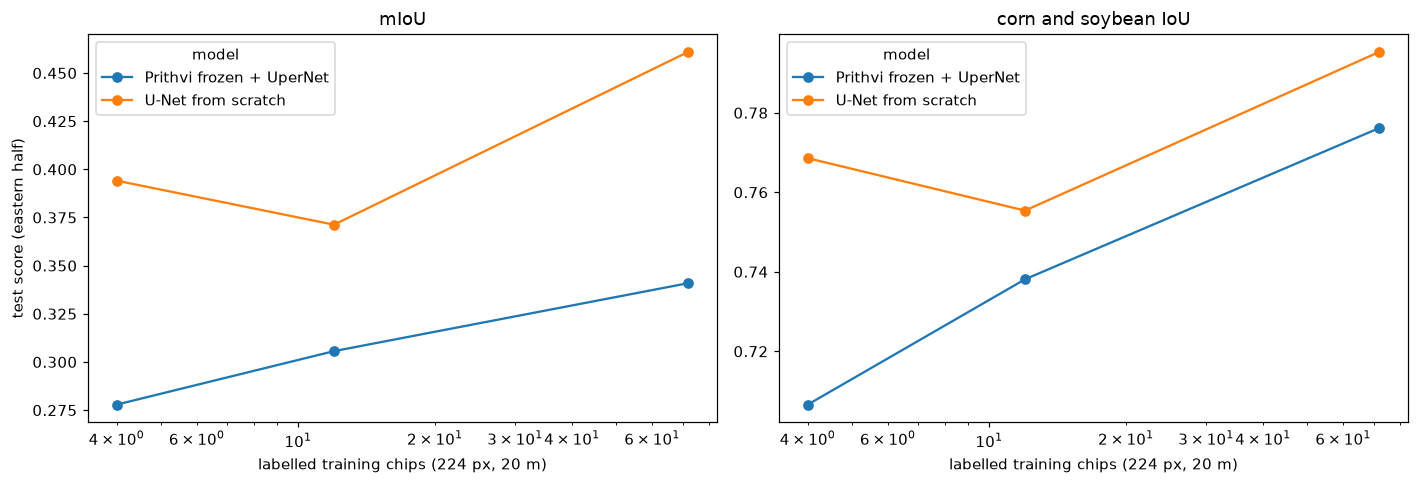

mIoU                        corn and soybean IoU  \
model Prithvi frozen + UperNet U-Net from scratch Prithvi frozen + UperNet   
chips                                                                        
4                        0.278              0.394                    0.707   
12                       0.306              0.371                    0.738   
72                       0.341              0.461                    0.776   

                          
model U-Net from scratch  
chips                     
4                  0.769  
12                 0.755  
72                 0.795

In [11]:
rows = []  # label efficiency results
rng = np.random.default_rng(SEED)  # random generator
for n_chips in [4, 12, len(train_idx)]:  # training set sizes
    sub = rng.choice(train_idx, n_chips, replace=False) if n_chips < len(train_idx) else train_idx  # a random subset
    ep = max(20, 20 * len(train_idx) // n_chips // 4)  # more epochs for tiny sets (similar number of updates)
    for name, r in [("U-Net from scratch", run(UNet(in_channels=6, classes=len(CLASSES)), sub, epochs=ep, lr=1e-3)),
                    ("Prithvi frozen + UperNet", run(prithvi(True), sub, epochs=ep, out=seg_out))]:  # both models
        rows.append({"chips": n_chips, "model": name, "mIoU": r["mIoU"], "corn and soybean IoU": (r["Corn"] + r["Soybeans"]) / 2})  # scores
eff = pd.DataFrame(rows).pivot(index="chips", columns="model")  # chips x (metric, model)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))  # two metrics
for a, m in zip(ax, ["mIoU", "corn and soybean IoU"]):  # every metric
    eff[m].plot(marker="o", logx=True, ax=a); a.set_title(m); a.set_xlabel("labelled training chips (224 px, 20 m)")  # curve
ax[0].set_ylabel("test score (eastern half)"); plt.tight_layout(); plt.show()  # draw
eff.round(3)

Pretraining does not pay off here, even with few labels. On the two main crops alone the U-Net trained
from scratch scores slightly higher than the frozen Prithvi with 4, 12 and 72 labelled chips, and the
gap in mean IoU over all classes is larger because of the thin classes. Three reasons are likely. A
224 pixel chip of 20 m data (4.5 km) holds a few dozen fields, so even 4 chips give the U-Net about a
hundred fields and 200,000 labelled pixels to learn spectral differences from. Prithvi's 320 m patches blur field edges and roads. And in
June the crops differ mainly in their spectra, which a small network learns quickly. Foundation models
earn their place with fewer labelled pixels, objects close to their patch size, other regions and
sensors (transfer), or when only embeddings, not training, are affordable. Measure before assuming.

## Summary and exercises

### Summary

- Prithvi, SSL4EO, Satlas and Scale-MAE each need their own bands, units and chip size;
  `embed_raster(norm="model", dense=True)` gives comparable patch-feature maps at native resolution.
- Late-season corn and soybeans are easy for any input; the early-season scene separates the encoders.
- Random cross-validation flatters every input on spatially correlated cells; spatial blocks give
  the honest estimate.
- Clustering embeddings without labels recovers the crop pattern only partly, and how well depends on
  the encoder and the date.
- `fm.segmentation_model` turns Prithvi into a crop segmenter with a UperNet decoder; freezing the
  encoder trains fastest, and the label efficiency curve shows where pretraining pays off.

### Exercises

1. Add `prithvi-eo-1.0-100m` to the probe comparison. Does the smaller, US-only model do worse?
2. Repeat the probes with the 15 May 2025 date. Which encoder keeps its advantage earliest?
3. Use 320 m cells (no averaging of ViT patches) for the probes; what changes for Satlas, whose cells are 640 m?
4. Train the fine-tuned Prithvi with 12 chips. Does unfreezing help or hurt with so few labels?
5. Replace the UperNet decoder with `decoder="FCNDecoder"` in `fm.segmentation_model` and compare speed and mIoU.

### References

- Bastani, F. et al. (2023). SatlasPretrain. ICCV.
- Jakubik, J. et al. (2023). Foundation models for generalist geospatial artificial intelligence (Prithvi). arXiv:2310.18660.
- Reed, C. J. et al. (2023). Scale-MAE: a scale-aware masked autoencoder for multiscale geospatial representation learning. ICCV.
- Szwarcman, D. et al. (2024). Prithvi-EO-2.0. arXiv:2412.02732.
- Wang, Y. et al. (2023). SSL4EO-S12. IEEE GRSM.
- Xiao, T. et al. (2018). Unified perceptual parsing for scene understanding (UperNet). ECCV.